In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


# Urban Intelligence Platform Using Big Data

## Project Members

**Name:** Mrigank Kasi Sahu  
**Register Number:** RA2411028010126  

**Name:** Anany Singh  
**Register Number:** RA2411028010097  

**Name:** Yuvan Vishnu Pandi  
**Register Number:** RA2411028010087  

## Department
**Networking and Communications**

---
**Academic Project Report**
Urban Intelligence Platform Using Big Data

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Traffic.csv to Traffic.csv


In [ ]:
df = pd.read_csv("Traffic.csv")


In [ ]:
df.head()

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,31,0,4,4,39,low
1,12:15:00 AM,10,Tuesday,49,0,3,3,55,low
2,12:30:00 AM,10,Tuesday,46,0,3,6,55,low
3,12:45:00 AM,10,Tuesday,51,0,2,5,58,low
4,1:00:00 AM,10,Tuesday,57,6,15,16,94,normal


In [ ]:
df.head(50)

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation
0,12:00:00 AM,10,Tuesday,31,0,4,4,39,low
1,12:15:00 AM,10,Tuesday,49,0,3,3,55,low
2,12:30:00 AM,10,Tuesday,46,0,3,6,55,low
3,12:45:00 AM,10,Tuesday,51,0,2,5,58,low
4,1:00:00 AM,10,Tuesday,57,6,15,16,94,normal
5,1:15:00 AM,10,Tuesday,44,0,5,4,53,low
6,1:30:00 AM,10,Tuesday,37,0,1,4,42,low
7,1:45:00 AM,10,Tuesday,42,4,4,5,55,low
8,2:00:00 AM,10,Tuesday,51,0,9,7,67,low
9,2:15:00 AM,10,Tuesday,34,0,4,7,45,low


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2976 entries, 0 to 2975
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Time               2976 non-null   object
 1   Date               2976 non-null   int64 
 2   Day of the week    2976 non-null   object
 3   CarCount           2976 non-null   int64 
 4   BikeCount          2976 non-null   int64 
 5   BusCount           2976 non-null   int64 
 6   TruckCount         2976 non-null   int64 
 7   Total              2976 non-null   int64 
 8   Traffic Situation  2976 non-null   object
dtypes: int64(6), object(3)
memory usage: 209.4+ KB


In [ ]:
df.shape


(2976, 9)

In [ ]:
df.describe()

,Date,CarCount,BikeCount,BusCount,TruckCount,Total
count,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000
mean,16.000000,68.696573,14.917339,15.279570,15.324933,114.218414
std,8.945775,45.850693,12.847518,14.341986,10.603833,60.190627
min,1.000000,6.000000,0.000000,0.000000,0.000000,21.000000
25%,8.000000,19.000000,5.000000,1.000000,6.000000,55.000000
50%,16.000000,64.000000,12.000000,12.000000,14.000000,109.000000
75%,24.000000,107.000000,22.000000,25.000000,23.000000,164.000000
max,31.000000,180.000000,70.000000,50.000000,40.000000,279.000000


In [ ]:
df.isnull().sum()

,0
Time,0
Date,0
Day of the week,0
CarCount,0
BikeCount,0
BusCount,0
TruckCount,0
Total,0
Traffic Situation,0


In [ ]:
df.fillna(df.mean(numeric_only=True), inplace=True)

In [ ]:
print(df.duplicated().sum())

0


In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df['Time'] = pd.to_datetime(df['Time'])

df['Hour'] = df['Time'].dt.hour

/tmp/ipykernel_2443/1343334345.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Time'] = pd.to_datetime(df['Time'])


In [ ]:
X = df[[
    'CarCount',
    'BikeCount',
    'BusCount',
    'TruckCount',
    'Total',
    'Hour'
]]

In [ ]:
X.head()

,CarCount,BikeCount,BusCount,TruckCount,Total,Hour
0,31,0,4,4,39,0
1,49,0,3,3,55,0
2,46,0,3,6,55,0
3,51,0,2,5,58,0
4,57,6,15,16,94,1


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
wcss = []

for i in range(1,11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

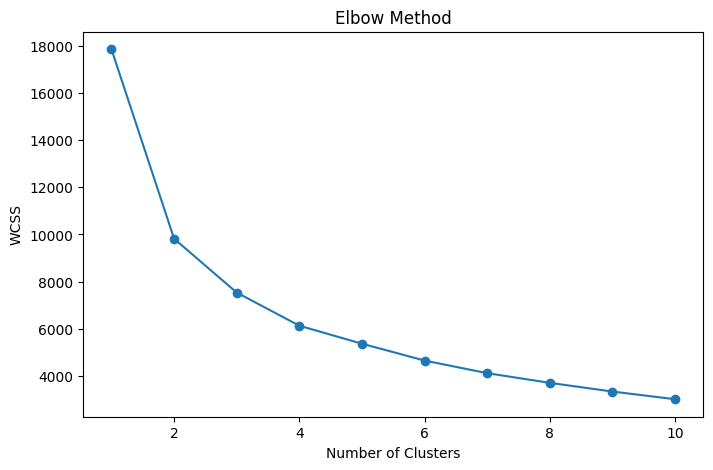

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1,11),
    wcss,
    marker='o'
)

plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.show()

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

In [ ]:
df['Cluster'] = clusters

In [ ]:
df.head()

,Time,Date,Day of the week,CarCount,BikeCount,BusCount,TruckCount,Total,Traffic Situation,Hour,Cluster
0,2026-10-05 00:00:00,10,Tuesday,31,0,4,4,39,low,0,2
1,2026-10-05 00:15:00,10,Tuesday,49,0,3,3,55,low,0,2
2,2026-10-05 00:30:00,10,Tuesday,46,0,3,6,55,low,0,2
3,2026-10-05 00:45:00,10,Tuesday,51,0,2,5,58,low,0,2
4,2026-10-05 01:00:00,10,Tuesday,57,6,15,16,94,normal,1,2


In [ ]:
df['Cluster'].value_counts()

,count
Cluster,
1,1217
3,805
2,652
0,302


In [ ]:
score = silhouette_score(
    X_scaled,
    clusters
)

print("Silhouette Score:", score)

Silhouette Score: 0.3417607716683686


In [ ]:
centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

cluster_centers = pd.DataFrame(
    centers,
    columns=X.columns
)

print(cluster_centers)

     CarCount  BikeCount   BusCount  TruckCount       Total       Hour
0   18.453333   3.000000   1.050000   22.106667   44.610000  21.940000
1   68.905505  15.064914  14.492194   16.185703  114.648316  13.296631
2   19.576453   3.587156   1.738532   23.496942   48.399083   3.136086
3  127.011180  28.340373  32.773913    4.857143  192.982609  11.688199


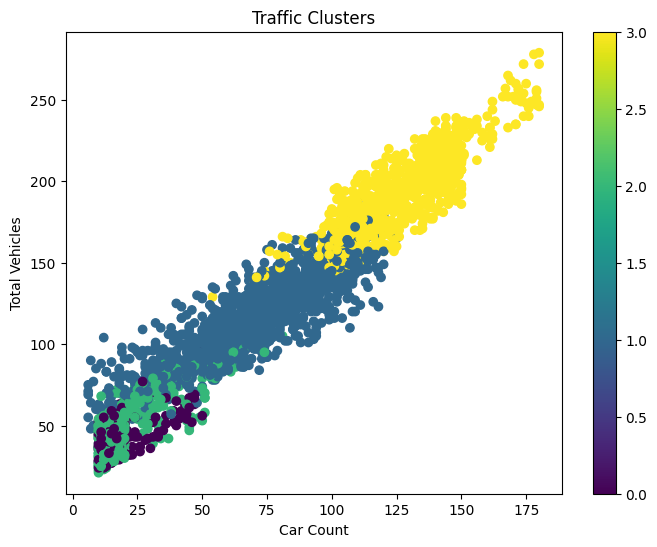

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    df['CarCount'],
    df['Total'],
    c=df['Cluster'],
    cmap='viridis'
)

plt.xlabel("Car Count")
plt.ylabel("Total Vehicles")
plt.title("Traffic Clusters")

plt.colorbar()

plt.show()